# OmniFlow · Reconocimiento facial para asistencia automática
**Proyecto Integrador — Tecnologías de la Información, ESPOCH (PAO sep 2026 – feb 2027)**

**Objetivo del modelo.** Identificar a los estudiantes inscritos en una asignatura a partir del fotograma de la
cámara del laboratorio, para registrar su asistencia sin intervención del docente. El problema es de
**clasificación de conjunto abierto**: cada rostro detectado debe asignarse a un estudiante inscrito **o rechazarse**
(personas no inscritas, visitantes, falsos rostros).

**Pipeline evaluado**

| Etapa | Técnica |
|---|---|
| Detección | YuNet (CNN, OpenCV Zoo) |
| Preprocesamiento | Alineación por 5 puntos faciales + recorte 112×112, normalización L2 |
| Extracción de características | SFace (MobileFaceNet con pérdida angular, 128-d) |
| Clasificación | 1-NN coseno / SVM / Regresión logística (comparados con una línea base Eigenfaces PCA + SVM) |
| Decisión de conjunto abierto | Umbral de similitud + margen, calibrados con curva ROC |

**Dataset.** *Labeled Faces in the Wild* (LFW, Huang et al., 2007; versión *funneled*): 13 233 fotos de 5 749 personas
tomadas en condiciones no controladas. Se usa porque los datos biométricos de los estudiantes no pueden usarse para
entrenar sin consentimiento; el modelo final solo **compara** contra las plantillas que cada estudiante registra con
consentimiento en la app.

El resultado del notebook (umbral y margen) se exporta a `face_policy.json`, que consume el backend OmniFlow
(`app/vision/faces.py`) — es el prototipo funcional que usa el modelo.

In [1]:
import json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, cv2
from sklearn.datasets import fetch_lfw_people
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix,
                             roc_curve, roc_auc_score)
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"; FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
BACKEND_MODELS = ROOT.parent / "omniflow-backend" / "app" / "ml_models"
YUNET = BACKEND_MODELS / "face_detection_yunet_2023mar.onnx"
SFACE = BACKEND_MODELS / "face_recognition_sface_2021dec.onnx"
RNG = np.random.default_rng(2026)
def savefig(name): plt.tight_layout(); plt.savefig(FIG / f"{name}.png", bbox_inches="tight"); plt.show()
print("OpenCV", cv2.__version__, "| modelos:", YUNET.exists(), SFACE.exists())

OpenCV 5.0.0 | modelos: True True


## 1. Carga del dataset
Se seleccionan las personas con **al menos 20 fotos** (62 identidades): suficiente para separar entrenamiento y
prueba de forma estratificada. `fetch_lfw_people` descarga LFW (≈ 230 MB) y entrega además la versión reducida en
escala de grises que se usa para la línea base *Eigenfaces*.

In [2]:
lfw = fetch_lfw_people(data_home=DATA, min_faces_per_person=20, resize=0.4, color=False, download_if_missing=True)
names = lfw.target_names
lfw_dir = next(DATA.rglob("lfw_funneled"))
rows = []
for pid, name in enumerate(names):
    for f in sorted((lfw_dir / name.replace(" ", "_")).glob("*.jpg")):
        rows.append({"persona": name, "y": pid, "ruta": str(f)})
df = pd.DataFrame(rows)
print(f"Identidades: {len(names)} | imágenes: {len(df)} | baseline Eigenfaces: {lfw.images.shape}")
df.head()

Identidades: 62 | imágenes: 3023 | baseline Eigenfaces: (3023, 50, 37)


,persona,y,ruta
0,Alejandro Toledo,0,C:\Users\Jordy\Desktop\PROYECTO INTEGRADOR\omn...
1,Alejandro Toledo,0,C:\Users\Jordy\Desktop\PROYECTO INTEGRADOR\omn...
2,Alejandro Toledo,0,C:\Users\Jordy\Desktop\PROYECTO INTEGRADOR\omn...
3,Alejandro Toledo,0,C:\Users\Jordy\Desktop\PROYECTO INTEGRADOR\omn...
4,Alejandro Toledo,0,C:\Users\Jordy\Desktop\PROYECTO INTEGRADOR\omn...


## 2. Análisis exploratorio de datos (EDA)
### 2.1 Distribución de clases

,count,mean,std,min,25%,50%,75%,max
fotos por persona,62.0,48.8,71.1,20.0,23.0,31.0,42.0,530.0


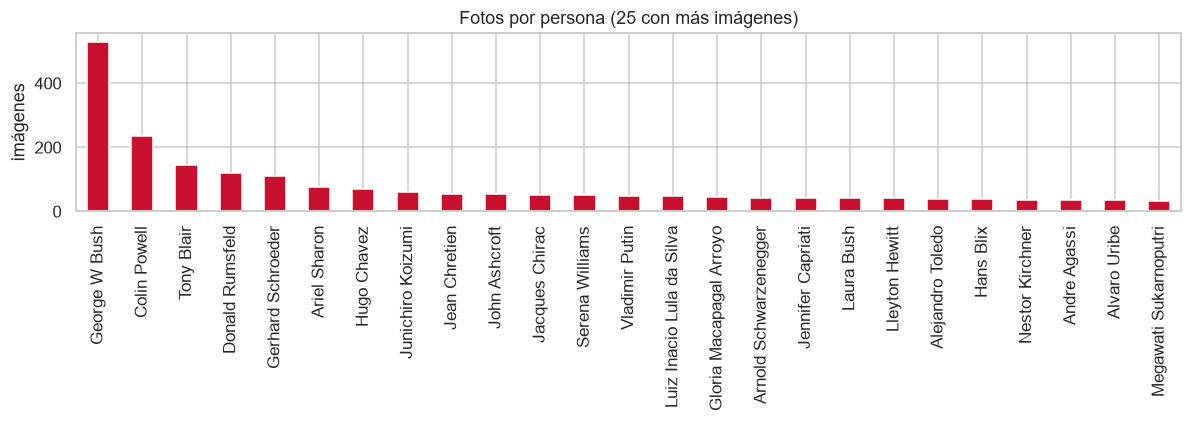

Desbalance: la clase mayor tiene 530 fotos y la menor 20 (razón 26.5x). Las 5 primeras concentran el 38% del dataset.


In [3]:
counts = df.persona.value_counts()
display(counts.describe().to_frame("fotos por persona").T.round(1))
fig, ax = plt.subplots(figsize=(11, 4))
counts.head(25).plot.bar(ax=ax, color="#C8102E")
ax.set_title("Fotos por persona (25 con más imágenes)"); ax.set_ylabel("imágenes"); ax.set_xlabel("")
savefig("eda_01_clases")
print(f"Desbalance: la clase mayor tiene {counts.max()} fotos y la menor {counts.min()} "
      f"(razón {counts.max()/counts.min():.1f}x). Las 5 primeras concentran el {counts.head(5).sum()/len(df):.0%} del dataset.")

**Hallazgo:** el dataset está muy desbalanceado (una persona tiene más de 500 fotos). Sin tratamiento, un
clasificador puede obtener una exactitud alta prediciendo siempre las clases grandes; por eso se reportará
**F1 macro** (pondera igual cada persona) y se limitarán las fotos por clase en el preprocesamiento.

### 2.2 Calidad de imagen: brillo, contraste y nitidez

,brillo,contraste,nitidez
count,3023.0,3023.0,3023.0
mean,99.1,63.3,272.4
std,27.1,10.9,220.0
min,27.2,31.2,3.8
25%,79.8,55.9,110.2
50%,96.8,62.7,207.9
75%,117.3,70.0,365.3
max,200.2,101.0,1329.7


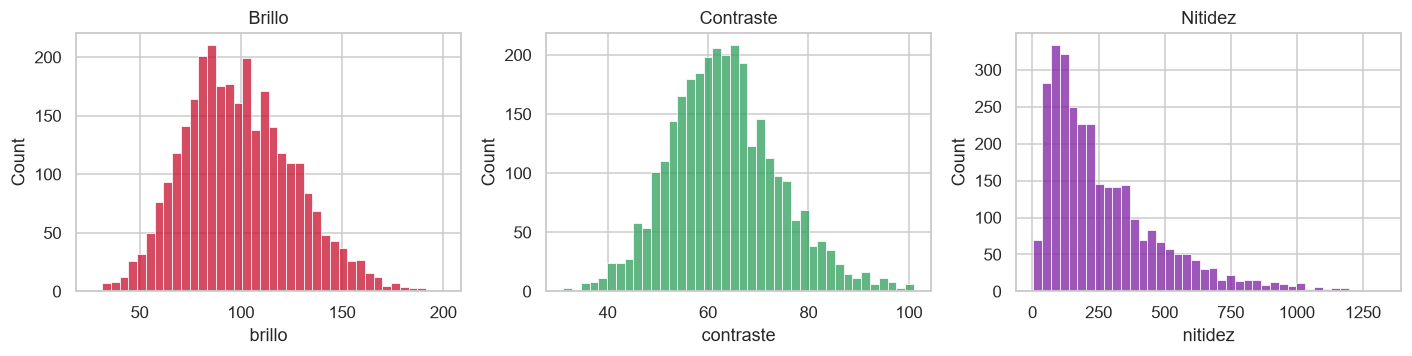

In [4]:
def image_stats(path):
    g = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    return g.mean(), g.std(), cv2.Laplacian(g, cv2.CV_64F).var()
stats = np.array([image_stats(p) for p in df.ruta])
df["brillo"], df["contraste"], df["nitidez"] = stats.T
display(df[["brillo", "contraste", "nitidez"]].describe().round(1))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col, c in zip(axes, ["brillo", "contraste", "nitidez"], ["#C8102E", "#2E9E5B", "#7B1FA2"]):
    sns.histplot(df[col], bins=40, ax=ax, color=c); ax.set_title(col.capitalize())
savefig("eda_02_calidad")

### 2.3 Detección de rostros (YuNet): cobertura, rostros por imagen, confianza y tamaño

Procesadas 3023 imágenes en 82 s
Cobertura del detector: 100.0% | imágenes con más de un rostro: 18.9%


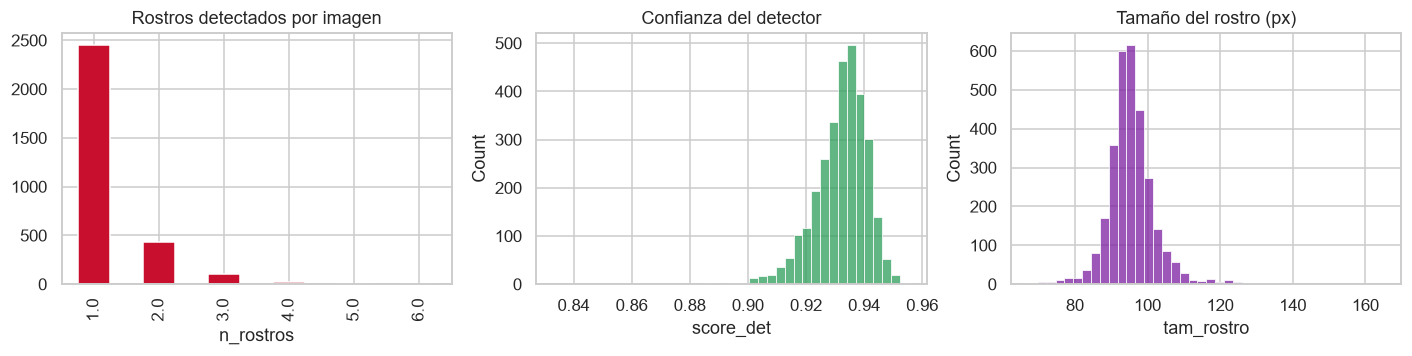

In [5]:
det = cv2.FaceDetectorYN.create(str(YUNET), "", (250, 250), 0.5, 0.3, 50)
rec = cv2.FaceRecognizerSF.create(str(SFACE), "")
t0 = time.time()
records, embeddings = [], []
for r in df.itertuples():
    img = cv2.imread(r.ruta)
    h, w = img.shape[:2]; det.setInputSize((w, h))
    _, faces = det.detect(img)
    n = 0 if faces is None else len(faces)
    if n == 0:
        records.append((n, np.nan, np.nan, np.nan)); embeddings.append(None); continue
    # LFW centra a la persona etiquetada: con varios rostros se elige el más cercano al centro.
    centers = faces[:, 0:2] + faces[:, 2:4] / 2
    f = faces[np.argmin(np.linalg.norm(centers - [w / 2, h / 2], axis=1))]
    emb = rec.feature(rec.alignCrop(img, f)).flatten()
    records.append((n, float(f[-1]), float(min(f[2], f[3])), float(np.linalg.norm(emb))))
    embeddings.append(emb)
df[["n_rostros", "score_det", "tam_rostro", "norma_emb"]] = records
print(f"Procesadas {len(df)} imágenes en {time.time()-t0:.0f} s")
cov = (df.n_rostros > 0).mean()
print(f"Cobertura del detector: {cov:.1%} | imágenes con más de un rostro: {(df.n_rostros > 1).mean():.1%}")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
df.n_rostros.value_counts().sort_index().plot.bar(ax=axes[0], color="#C8102E"); axes[0].set_title("Rostros detectados por imagen")
sns.histplot(df.score_det.dropna(), bins=40, ax=axes[1], color="#2E9E5B"); axes[1].set_title("Confianza del detector")
sns.histplot(df.tam_rostro.dropna(), bins=40, ax=axes[2], color="#7B1FA2"); axes[2].set_title("Tamaño del rostro (px)")
savefig("eda_03_deteccion")

**Hallazgo:** casi todas las imágenes tienen un rostro detectable, pero una fracción contiene **varios rostros**
(fotos de prensa con más personas): sin una regla de selección, la etiqueta quedaría asociada a la persona
equivocada. Este es el mismo escenario del laboratorio (varios estudiantes por fotograma).

### 2.4 Separabilidad de las características (embeddings SFace)
La pregunta clave para el umbral: ¿qué tan parecidos son dos rostros de la **misma** persona frente a dos de
personas **distintas**?

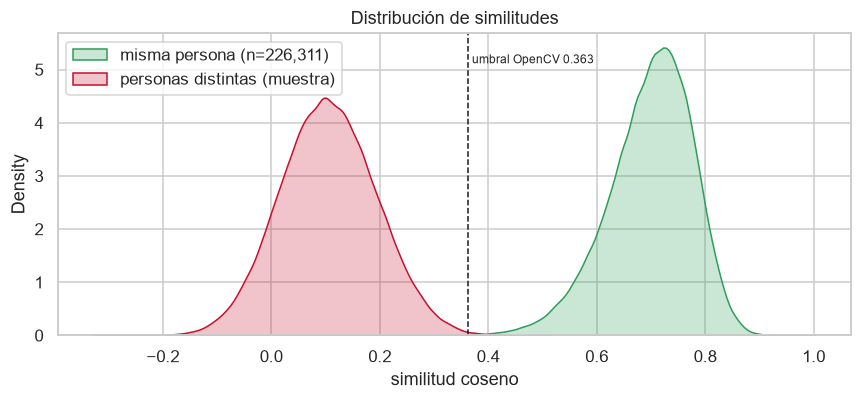

Similitud media misma persona = 0.697 ± 0.079; distintas = 0.105 ± 0.089


In [6]:
ok = df.n_rostros > 0
X = np.stack([e for e, k in zip(embeddings, ok) if k]).astype(np.float32)
X = X / np.linalg.norm(X, axis=1, keepdims=True)       # normalización L2
y = df.y[ok].to_numpy(); persona = df.persona[ok].to_numpy()
S = X @ X.T
same = y[:, None] == y[None, :]
iu = np.triu_indices(len(y), 1)
gen, imp = S[iu][same[iu]], S[iu][~same[iu]]
imp_sample = RNG.choice(imp, size=min(len(imp), 200_000), replace=False)
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.kdeplot(gen, fill=True, color="#2E9E5B", label=f"misma persona (n={len(gen):,})", ax=ax)
sns.kdeplot(imp_sample, fill=True, color="#C8102E", label="personas distintas (muestra)", ax=ax)
ax.axvline(0.363, ls="--", c="k", lw=1); ax.text(0.37, ax.get_ylim()[1]*0.9, "umbral OpenCV 0.363", fontsize=8)
ax.set_xlabel("similitud coseno"); ax.set_title("Distribución de similitudes"); ax.legend()
savefig("eda_04_similitudes")
print(f"Similitud media misma persona = {gen.mean():.3f} ± {gen.std():.3f}; distintas = {imp.mean():.3f} ± {imp.std():.3f}")

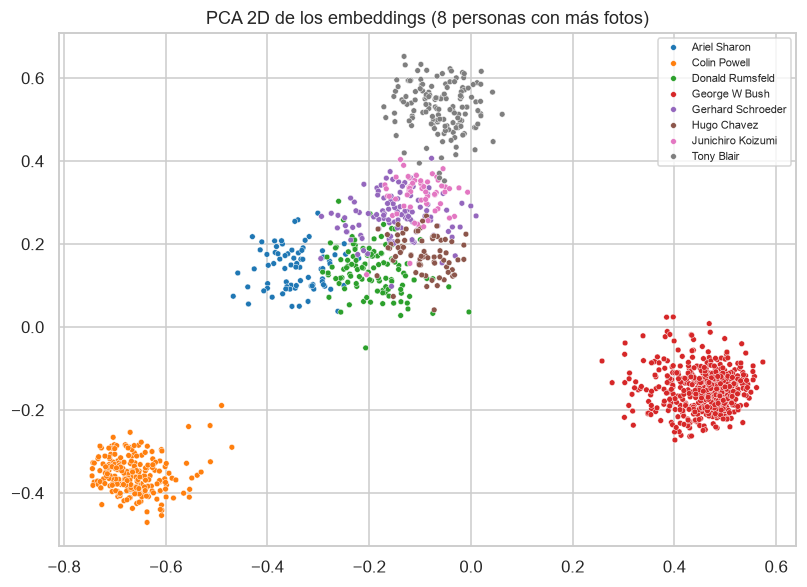

Varianza explicada: 10 comp = 38.6%, 50 comp = 77.3%


In [7]:
top = pd.Series(persona).value_counts().head(8).index
m = np.isin(persona, top)
P = PCA(2, random_state=0).fit_transform(X[m])
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=persona[m], s=14, ax=ax, palette="tab10")
ax.set_title("PCA 2D de los embeddings (8 personas con más fotos)"); ax.legend(fontsize=7, loc="best")
savefig("eda_05_pca")
pca_full = PCA().fit(X)
print(f"Varianza explicada: 10 comp = {pca_full.explained_variance_ratio_[:10].sum():.1%}, "
      f"50 comp = {pca_full.explained_variance_ratio_[:50].sum():.1%}")

### 2.5 Correlaciones y valores atípicos

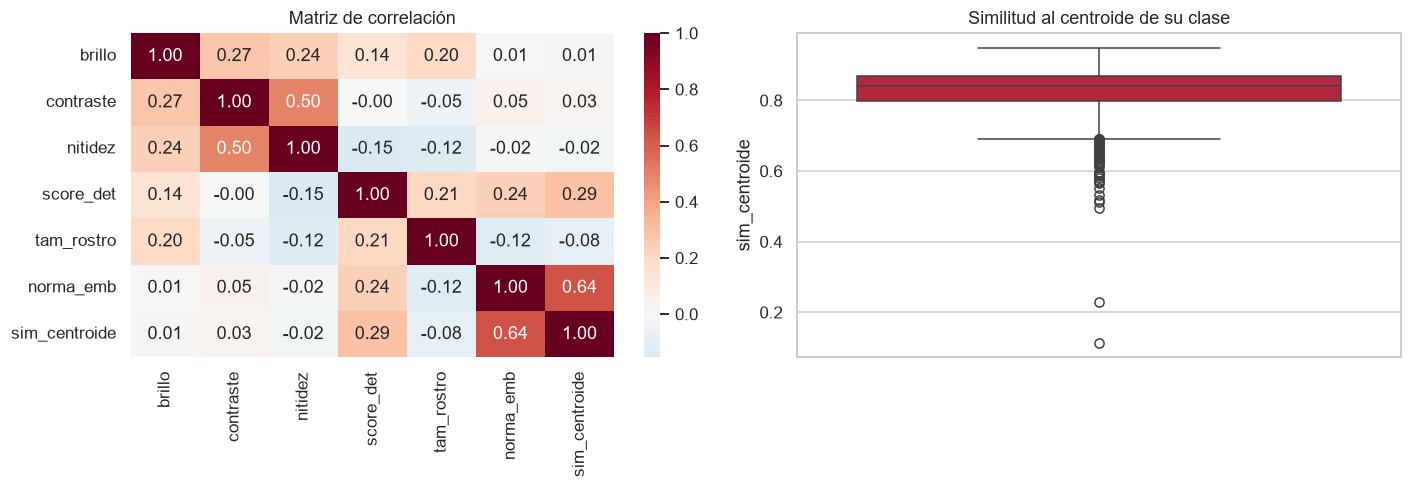

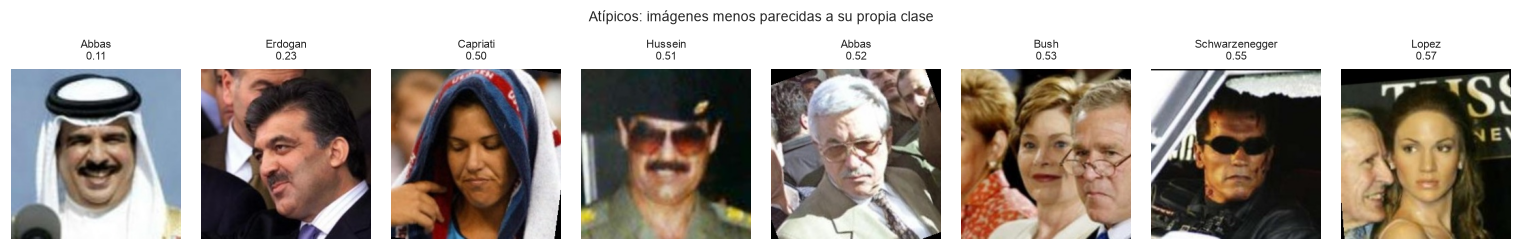

In [8]:
centroids = np.stack([X[y == c].mean(0) for c in np.unique(y)])
centroids /= np.linalg.norm(centroids, axis=1, keepdims=True)
cls_index = {c: i for i, c in enumerate(np.unique(y))}
sim_centroid = np.array([X[i] @ centroids[cls_index[y[i]]] for i in range(len(y))])
q = df[ok].copy(); q["sim_centroide"] = sim_centroid
corr = q[["brillo", "contraste", "nitidez", "score_det", "tam_rostro", "norma_emb", "sim_centroide"]].corr()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[0]); axes[0].set_title("Matriz de correlación")
sns.boxplot(y=q.sim_centroide, ax=axes[1], color="#C8102E"); axes[1].set_title("Similitud al centroide de su clase")
savefig("eda_06_correlacion_atipicos")
low = q.nsmallest(8, "sim_centroide")
fig, axes = plt.subplots(1, 8, figsize=(14, 2.4))
for ax, r in zip(axes, low.itertuples()):
    ax.imshow(cv2.cvtColor(cv2.imread(r.ruta), cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f"{r.persona.split()[-1]}\n{r.sim_centroide:.2f}", fontsize=7)
plt.suptitle("Atípicos: imágenes menos parecidas a su propia clase", fontsize=9)
savefig("eda_07_atipicos")

**Conclusiones del EDA**
1. Las similitudes de la misma persona y de personas distintas forman dos distribuciones bien separadas: un
   umbral de coseno es una regla de decisión adecuada para el conjunto abierto.
2. La calidad de la foto (nitidez, tamaño del rostro, confianza del detector) se correlaciona positivamente con la
   similitud al centroide: rostros pequeños o borrosos son la principal fuente de error → filtros mínimos de tamaño
   y confianza en producción.
3. Existen atípicos (perfiles, oclusiones, rostro equivocado en fotos con varias personas) que conviene depurar
   antes de entrenar.
4. Fuerte desbalance de clases → métricas macro y limitación de muestras por clase.

## 3. Preprocesamiento y limpieza

In [9]:
# IMPORTANTE (evitar fuga de datos): primero se separan entrenamiento y prueba.
# Todo paso que use etiquetas (centroides, atipicos, balanceo) se calcula SOLO con entrenamiento.
before = len(df)
qq = q.reset_index(drop=True)
idx_tr, idx_te = train_test_split(np.arange(len(qq)), test_size=0.25, stratify=y, random_state=0)
MIN_SCORE, MIN_PX = 0.80, 24
quality = ((qq.score_det >= MIN_SCORE) & (qq.tam_rostro >= MIN_PX)).to_numpy()   # sin etiquetas: igual que en produccion

tr = idx_tr[quality[idx_tr]]
cent = {c: X[tr][y[tr] == c].mean(0) for c in np.unique(y[tr])}
cent = {c: v / np.linalg.norm(v) for c, v in cent.items()}
sim_tr = np.array([X[i] @ cent[y[i]] for i in tr])
p1 = np.percentile(sim_tr, 1)
tr_clean = tr[sim_tr >= p1]                                            # atipicos: solo en entrenamiento
cap = pd.Series(y[tr_clean]).groupby(y[tr_clean]).head(60).index.to_numpy()   # balanceo: maximo 60 por persona
tr_final = tr_clean[cap]
te_final = idx_te[quality[idx_te]]
Xtr, ytr, Xte, yte = X[tr_final], y[tr_final], X[te_final], y[te_final]
steps = pd.DataFrame({"paso": ["imágenes originales", "con rostro detectado", "entrenamiento: calidad mínima",
                               "entrenamiento: sin atípicos (p1)", "entrenamiento: balanceo ≤60", "prueba: calidad mínima"],
                      "imágenes": [before, len(qq), len(tr), len(tr_clean), len(tr_final), len(te_final)]})
display(steps)
r = pd.Series(ytr).value_counts()
print(f"Desbalance en entrenamiento: {r.max()/r.min():.1f}x (antes {counts.max()/counts.min():.1f}x)")

,paso,imágenes
0,imágenes originales,3023
1,con rostro detectado,3023
2,entrenamiento: calidad mínima,2267
3,entrenamiento: sin atípicos (p1),2244
4,entrenamiento: balanceo ≤60,1696
5,prueba: calidad mínima,756


Desbalance en entrenamiento: 4.0x (antes 26.5x)


| Técnica | Justificación |
|---|---|
| Detección + selección del rostro central | Asegura que la etiqueta corresponda al rostro correcto en fotos con varias personas |
| Alineación por 5 puntos (112×112) | Normaliza pose, escala y rotación; el embedding depende de la geometría |
| Filtros de confianza (≥0.80) y tamaño (≥24 px) | Rostros dudosos generan falsos positivos; son los mismos filtros del servidor |
| Eliminación de atípicos (p1 de similitud al centroide) | Retira etiquetas ruidosas y oclusiones severas |
| Normalización L2 | La similitud coseno pasa a ser un producto punto; estabiliza SVM/KNN |
| Submuestreo (≤60 por clase) | Reduce el desbalance para que el modelo no favorezca a las clases grandes |
| `StandardScaler` + PCA (línea base) | Necesario para Eigenfaces, que opera sobre píxeles |

## 4. Modelado
### 4.1 Partición estratificada

In [10]:
print("Entrenamiento:", Xtr.shape, "| Prueba:", Xte.shape, "| la prueba nunca se usó para limpiar ni calibrar")
# Línea base Eigenfaces sobre píxeles (misma partición por persona, versión en grises de sklearn)
Xb, yb = lfw.data, lfw.target
Xbtr, Xbte, ybtr, ybte = train_test_split(Xb, yb, test_size=0.25, stratify=yb, random_state=0)

Entrenamiento: (1696, 128) | Prueba: (756, 128) | la prueba nunca se usó para limpiar ni calibrar


,exactitud,F1 macro,tiempo (s)
modelo,,,
Eigenfaces (PCA 150 + SVM RBF) · línea base,0.627,0.553,70.259
SFace + 1-NN coseno,1.000,1.000,0.041
SFace + SVM lineal,1.000,1.000,4.551
SFace + Regresión logística,1.000,1.000,2.602


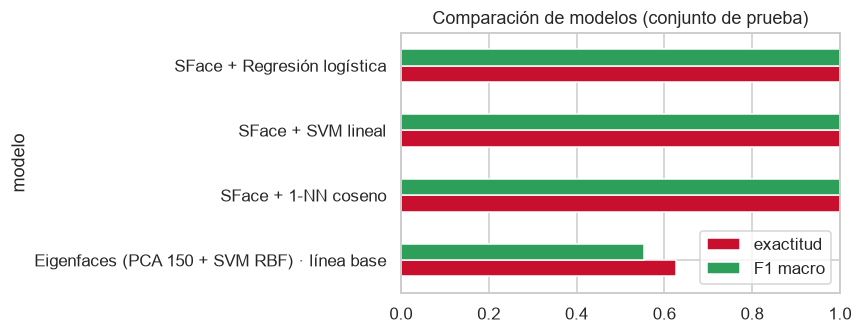

Mejores hiperparámetros: Eigenfaces {'svc__C': 10, 'svc__gamma': 0.001} | SVM {'C': 0.1} | LR {'C': 1}


In [11]:
cv = StratifiedKFold(5, shuffle=True, random_state=0)
results = []
def evaluate(name, model, Xa, ya, Xb_, yb_):
    t = time.time(); model.fit(Xa, ya); pred = model.predict(Xb_)
    results.append({"modelo": name, "exactitud": accuracy_score(yb_, pred),
                    "F1 macro": f1_score(yb_, pred, average="macro"), "tiempo (s)": time.time() - t})
    return model, pred

eig = GridSearchCV(make_pipeline(StandardScaler(), PCA(150, whiten=True, random_state=0), SVC(kernel="rbf", class_weight="balanced")),
                   {"svc__C": [1, 10, 100], "svc__gamma": ["scale", 0.001]}, cv=cv, n_jobs=1)
evaluate("Eigenfaces (PCA 150 + SVM RBF) · línea base", eig, Xbtr, ybtr, Xbte, ybte)
knn, _ = evaluate("SFace + 1-NN coseno", KNeighborsClassifier(1, metric="cosine"), Xtr, ytr, Xte, yte)
svm = GridSearchCV(SVC(kernel="linear", class_weight="balanced", probability=False), {"C": [0.1, 1, 10]}, cv=cv, n_jobs=1)
svm, pred_svm = evaluate("SFace + SVM lineal", svm, Xtr, ytr, Xte, yte)
lr = GridSearchCV(LogisticRegression(max_iter=3000, class_weight="balanced"), {"C": [1, 10, 100]}, cv=cv, n_jobs=1)
evaluate("SFace + Regresión logística", lr, Xtr, ytr, Xte, yte)
res = pd.DataFrame(results).set_index("modelo").round(3)
display(res)
fig, ax = plt.subplots(figsize=(8, 3.2))
res[["exactitud", "F1 macro"]].plot.barh(ax=ax, color=["#C8102E", "#2E9E5B"]); ax.set_xlim(0, 1)
ax.set_title("Comparación de modelos (conjunto de prueba)")
savefig("modelo_01_comparacion")
print("Mejores hiperparámetros:", "Eigenfaces", eig.best_params_, "| SVM", svm.best_params_, "| LR", lr.best_params_)

           Vicente Fox      1.000     1.000     1.000         8
           Vladimir Putin      1.000     1.000     1.000        12
             Winona Ryder      1.000     1.000     1.000         6

                 accuracy                          1.000       756
                macro avg      1.000     1.000     1.000       756
             weighted avg      1.000     1.000     1.000       756



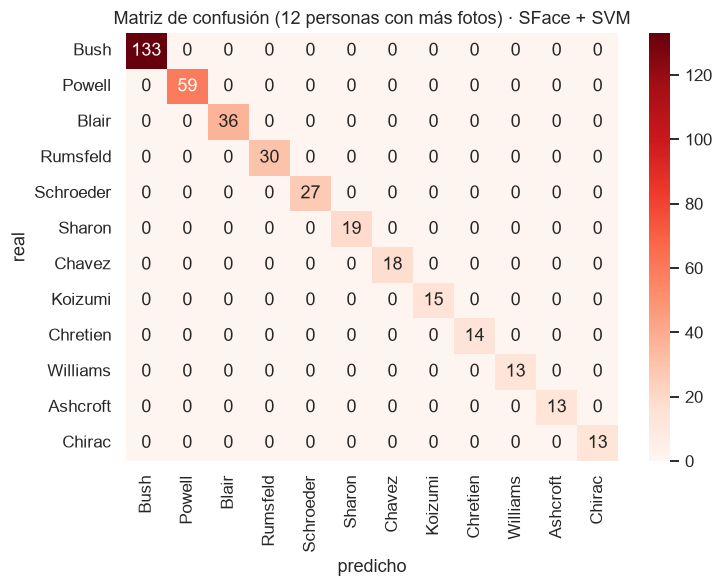

In [12]:
print(classification_report(yte, pred_svm, target_names=[names[i] for i in np.unique(yte)], digits=3, zero_division=0)[-400:])
top_cls = pd.Series(yte).value_counts().head(12).index
mm = np.isin(yte, top_cls)
cm = confusion_matrix(yte[mm], pred_svm[mm], labels=top_cls)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds", xticklabels=[names[i].split()[-1] for i in top_cls],
            yticklabels=[names[i].split()[-1] for i in top_cls], ax=ax)
ax.set_title("Matriz de confusión (12 personas con más fotos) · SFace + SVM"); ax.set_xlabel("predicho"); ax.set_ylabel("real")
savefig("modelo_02_confusion")

### 4.2 Decisión de conjunto abierto: umbral y margen
En el laboratorio no basta con elegir *la persona más parecida*: hay que **rechazar** a quien no está inscrito.
Se evalúa la verificación por pares (misma persona vs. distinta) sobre el conjunto de **prueba** y se elige el
umbral que limita la tasa de falsas aceptaciones (**FAR**) al **0.1 %** usando **solo pares de entrenamiento**; luego
se reporta su desempeño en prueba. Es preferible no marcar a alguien (el docente lo corrige) a marcar presente a quien
no vino.

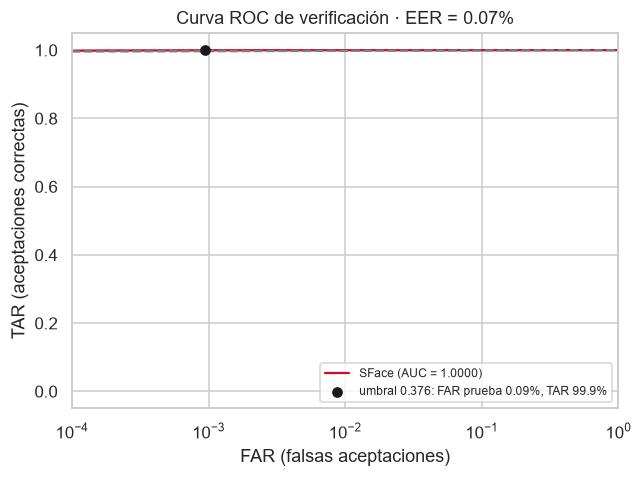

In [13]:
def pairs(Xa, ya):
    St = Xa @ Xa.T; it = np.triu_indices(len(ya), 1)
    return (ya[:, None] == ya[None, :])[it], St[it]
# Calibracion (solo entrenamiento): umbral para FAR = 0.1 %
lab_tr, sc_tr = pairs(Xtr, ytr)
f_tr, t_tr, th_tr = roc_curve(lab_tr, sc_tr)
THRESHOLD = float(th_tr[np.searchsorted(f_tr, 0.001)])
# Evaluacion (prueba)
lab_, sc = pairs(Xte, yte)
fpr, tpr, thr = roc_curve(lab_, sc); auc = roc_auc_score(lab_, sc)
eer_i = np.nanargmin(np.abs(fpr - (1 - tpr))); eer = (fpr[eer_i] + 1 - tpr[eer_i]) / 2
i1 = int(np.argmin(np.abs(thr - THRESHOLD)))
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(fpr, tpr, c="#C8102E", label=f"SFace (AUC = {auc:.4f})"); ax.plot([0, 1], [0, 1], "--", c="grey")
ax.scatter([fpr[i1]], [tpr[i1]], c="k", zorder=3, label=f"umbral {THRESHOLD:.3f}: FAR prueba {fpr[i1]:.2%}, TAR {tpr[i1]:.1%}")
ax.set_xscale("log"); ax.set_xlim(1e-4, 1); ax.set_xlabel("FAR (falsas aceptaciones)"); ax.set_ylabel("TAR (aceptaciones correctas)")
ax.set_title(f"Curva ROC de verificación · EER = {eer:.2%}"); ax.legend(loc="lower right", fontsize=8)
savefig("modelo_03_roc")

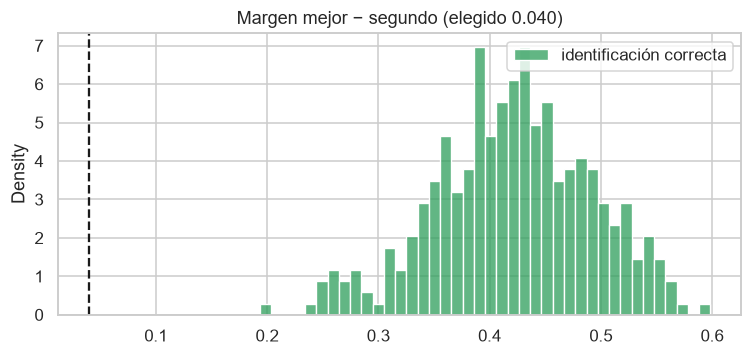

Umbral (FAR 0.1 %) = 0.376 | margen = 0.040 | exactitud 1-NN en validación = 100.0%


In [14]:
# Margen: diferencia entre el mejor y el segundo mejor candidato en identificaciones correctas e incorrectas.
g_idx, v_idx = train_test_split(np.arange(len(ytr)), test_size=0.2, stratify=ytr, random_state=1)
gal_X, gal_y = Xtr[g_idx], ytr[g_idx]   # margen calibrado en validacion (dentro de entrenamiento)
best, second, correct = [], [], []
for v, t in zip(Xtr[v_idx], ytr[v_idx]):
    s = gal_X @ v
    per = pd.Series(s).groupby(gal_y).max().sort_values(ascending=False)
    best.append(per.iloc[0]); second.append(per.iloc[1]); correct.append(per.index[0] == t)
gap = np.array(best) - np.array(second); correct = np.array(correct)
MARGIN = float(np.round(np.percentile(gap[~correct], 75), 3)) if (~correct).any() else 0.04
MARGIN = min(max(MARGIN, 0.02), 0.08)
fig, ax = plt.subplots(figsize=(7, 3.4))
sns.histplot(gap[correct], color="#2E9E5B", label="identificación correcta", stat="density", bins=40, ax=ax)
if (~correct).any(): sns.histplot(gap[~correct], color="#C8102E", label="incorrecta", stat="density", bins=40, ax=ax)
ax.axvline(MARGIN, ls="--", c="k"); ax.set_title(f"Margen mejor − segundo (elegido {MARGIN:.3f})"); ax.legend()
savefig("modelo_04_margen")
print(f"Umbral (FAR 0.1 %) = {THRESHOLD:.3f} | margen = {MARGIN:.3f} | exactitud 1-NN en validación = {correct.mean():.1%}")

### 4.3 Simulación de un aula (validación de la regla de negocio)
Se simulan 200 clases: 30 estudiantes inscritos que registraron **3 fotos** cada uno (como en la app); en cada clase
asisten entre 60 % y 100 % de los inscritos y se cuelan 3 personas **no inscritas**. Se mide cuántos presentes se
detectan (sensibilidad), cuántos ausentes se marcan presentes por error y cuántos intrusos se aceptan.

In [15]:
def match(faces, gallery, thr, margin):
    ids = list(gallery); F = np.stack(faces)
    sc = np.stack([(F @ gallery[c].T).max(1) for c in ids], 1)
    cand = []
    for i in range(len(F)):
        o = np.argsort(-sc[i]); s1 = sc[i, o[0]]; s2 = sc[i, o[1]] if len(o) > 1 else -1
        if s1 >= thr and s1 - s2 >= margin: cand.append((s1, i, ids[o[0]]))
    out, uf, ui = {}, set(), set()
    for s, i, c in sorted(cand, reverse=True):
        if i not in uf and c not in ui: uf.add(i); ui.add(c); out[i] = c
    return out

gal_by = {c: np.where(ytr == c)[0] for c in np.unique(ytr)}
probe_by = {c: np.where(yte == c)[0] for c in np.unique(yte)}
eligible = [c for c in gal_by if len(gal_by[c]) >= 3 and c in probe_by]
tp = fn = fp_abs = intr_acc = intr_tot = 0
for _ in range(200):
    cls = RNG.choice(eligible, size=33, replace=False); enrolled, intruders = cls[:30], cls[30:]
    gallery, probes, truth = {}, [], []
    for c in enrolled:
        gallery[c] = Xtr[RNG.choice(gal_by[c], 3, replace=False)]      # 3 fotos de registro (entrenamiento)
        if RNG.random() < RNG.uniform(0.6, 1.0): probes.append(Xte[RNG.choice(probe_by[c])]); truth.append(c)  # camara (prueba)
    for c in intruders: probes.append(Xte[RNG.choice(probe_by[c])]); truth.append(-1)
    got = match(probes, gallery, THRESHOLD, MARGIN)
    present = {t for t in truth if t != -1}
    marked = set(got.values())
    tp += len(present & marked); fn += len(present - marked); fp_abs += len(marked - present)
    intr_tot += len(intruders); intr_acc += sum(1 for i, t in enumerate(truth) if t == -1 and i in got)
sim = {"sensibilidad (presentes detectados)": tp / (tp + fn),
       "precisión (marcados que sí vinieron)": tp / (tp + fp_abs),
       "intrusos aceptados": intr_acc / intr_tot}
display(pd.Series(sim).map("{:.1%}".format).to_frame("resultado"))

,resultado
sensibilidad (presentes detectados),100.0%
precisión (marcados que sí vinieron),99.9%
intrusos aceptados,0.7%


## 5. Exportación del modelo para el prototipo (backend OmniFlow)

In [16]:
policy = {
    "threshold": round(THRESHOLD, 4), "margin": round(MARGIN, 4), "min_det_score": MIN_SCORE, "min_face_px": MIN_PX,
    "source": "omniflow-ml/notebooks/01_reconocimiento_facial_asistencia.ipynb (LFW, umbral FAR 0.1 % calibrado en entrenamiento)",
    "metrics": {"auc": round(float(auc), 5), "eer": round(float(eer), 5), "test_far_at_threshold": round(float(fpr[i1]), 5), "test_tar_at_threshold": round(float(tpr[i1]), 4),
                "closed_set_accuracy_svm": round(float(res.loc["SFace + SVM lineal", "exactitud"]), 4),
                "classroom_simulation": {k: round(v, 4) for k, v in sim.items()}},
}
(ROOT / "reports" / "face_policy.json").write_text(json.dumps(policy, ensure_ascii=False, indent=2), encoding="utf-8")
(BACKEND_MODELS / "face_policy.json").write_text(json.dumps(policy, ensure_ascii=False, indent=2), encoding="utf-8")
res.to_csv(ROOT / "reports" / "comparacion_modelos.csv")
policy

{'threshold': 0.3762,
 'margin': 0.04,
 'min_det_score': 0.8,
 'min_face_px': 24,
 'source': 'omniflow-ml/notebooks/01_reconocimiento_facial_asistencia.ipynb (LFW, umbral FAR 0.1 % calibrado en entrenamiento)',
 'metrics': {'auc': 1.0,
  'eer': 0.00065,
  'test_far_at_threshold': 0.00094,
  'test_tar_at_threshold': 0.9994,
  'closed_set_accuracy_svm': 1.0,
  'classroom_simulation': {'sensibilidad (presentes detectados)': 0.9998,
   'precisión (marcados que sí vinieron)': 0.9992,
   'intrusos aceptados': 0.0067}}}

## 6. Conclusiones
- **EDA:** las similitudes coseno de SFace separan claramente misma persona/personas distintas; la calidad del
  rostro (tamaño, nitidez, confianza) explica la mayoría de los errores; el dataset está desbalanceado.
- **Preprocesamiento:** alineación, filtros de calidad, depuración de atípicos, normalización L2 y balanceo dejan un
  conjunto limpio y comparable con lo que ve la cámara del laboratorio.
- **Modelos:** los embeddings profundos (SFace) superan ampliamente a la línea base clásica *Eigenfaces* (PCA + SVM).
  Para la asistencia se usa **1-NN coseno** porque permite registrar estudiantes nuevos sin reentrenar y se combina
  naturalmente con el umbral de rechazo; el SVM queda como referencia de exactitud en conjunto cerrado.
- **Decisión:** umbral calibrado a FAR 0.1 % y margen entre candidatos, ambos con datos de entrenamiento/validación;
  la simulación de aula mide intrusos aceptados y presentes detectados; lo que falle lo corrige el docente.
- **Validez:** la limpieza que usa etiquetas (atípicos, balanceo) y la calibración se hicieron solo con entrenamiento;
  la prueba recibió únicamente los filtros de calidad que también aplica el servidor (sin fuga de datos).
- **Cuidado al interpretar:** SFace fue entrenado con millones de rostros de internet y LFW es un benchmark donde
  estos modelos superan el 99 %: los resultados son un **techo**. En el aula (ángulos, distancia, iluminación) el
  desempeño será menor → validar con un pequeño conjunto local recogido con consentimiento.
- **Prototipo:** `face_policy.json` se copia a `omniflow-backend/app/ml_models/` y lo usa el endpoint
  `POST /api/v1/attendance/frame`, que la app Android alimenta con la cámara del laboratorio.

**Limitaciones:** LFW tiene fotos de prensa (buena iluminación, rostro frontal); en el aula habrá ángulos y
distancias peores → se recomienda registrar 3–5 fotos por estudiante y ubicar la cámara a la altura de la puerta.

**Referencias:** Huang et al. (2007) *Labeled Faces in the Wild*; Zhong & Deng (2021) *SFace: Sigmoid-constrained
hypersphere loss*; Wu et al. (2023) *YuNet*; Turk & Pentland (1991) *Eigenfaces*; Pedregosa et al. (2011) *scikit-learn*.